# RetailMart Sales Analysis – Python Mini Project
**BBA III Semester | Data Analysis using Python (BBADSE26303D) | IPS Academy, IBMR Indore**

**Objective:** Analyse one year of RetailMart sales data (Apr 2025 – Mar 2026) and give the owner clear, data-backed advice.

**Contents**
1. Import libraries & load data
2. Data cleaning
3. Net sales & key metrics
4. Group-wise analysis (city, category, month, top products)
5. Charts
6. Insights & recommendations

## 1. Import Libraries & Load Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
os.makedirs("charts", exist_ok=True)

df = pd.read_csv("retailmart_sales database.csv")
print("Shape:", df.shape)
df.head()

Shape: (510, 11)


,order_id,order_date,customer_id,city,category,product,quantity,unit_price,discount_pct,payment_mode,customer_rating
0,1355,2025-09-20,C044,Bhopal,Home & Kitchen,Mixer Grinder,3,2299,0,Card,3.0
1,1298,2025-11-17,C140,Dewas,Clothing,Kurta,2,899,0,UPI,4.0
2,1301,2025-04-05,C158,Jabalpur,Beauty,Shampoo,4,329,20,Net Banking,1.0
3,1426,2025-04-10,C014,Jabalpur,Electronics,Earphones,3,799,10,Cash,3.0
4,1322,2025-07-20,C130,Bhopal,Electronics,Power Bank,4,1299,15,Card,2.0


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 510 entries, 0 to 509
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   order_id         510 non-null    int64  
 1   order_date       510 non-null    str    
 2   customer_id      510 non-null    str    
 3   city             510 non-null    str    
 4   category         510 non-null    str    
 5   product          510 non-null    str    
 6   quantity         510 non-null    int64  
 7   unit_price       510 non-null    int64  
 8   discount_pct     510 non-null    int64  
 9   payment_mode     498 non-null    str    
 10  customer_rating  490 non-null    float64
dtypes: float64(1), int64(4), str(6)
memory usage: 44.0 KB


In [3]:
df.describe()

,order_id,quantity,unit_price,discount_pct,customer_rating
count,510.000000,510.000000,510.000000,510.000000,490.000000
mean,1250.317647,2.996078,957.121569,7.656863,2.977551
std,144.900579,1.453937,714.874922,6.962565,1.395840
min,1001.000000,-1.000000,160.000000,0.000000,1.000000
25%,1124.250000,2.000000,380.000000,0.000000,2.000000
50%,1250.500000,3.000000,799.000000,5.000000,3.000000
75%,1374.750000,4.000000,1299.000000,15.000000,4.000000
max,1500.000000,5.000000,2499.000000,20.000000,5.000000


## 2. Data Cleaning
First we check the problems in the raw data.

In [4]:
print("Duplicate rows        :", df.duplicated().sum())
print("Invalid quantity (<=0):", (df["quantity"] <= 0).sum())
print("Missing values:\n", df.isnull().sum()[df.isnull().sum() > 0])
print("\nCity spellings:\n", df["city"].value_counts())

Duplicate rows        : 10
Invalid quantity (<=0): 8
Missing values:
 payment_mode       12
customer_rating    20
dtype: int64

City spellings:
 city
Indore      207
Bhopal      104
Jabalpur     62
Ujjain       59
Dewas        38
indore        7
INDORE        7
BHOPAL        6
DEWAS         5
UJJAIN        5
bhopal        5
dewas         2
JABALPUR      2
ujjain        1
Name: count, dtype: int64


### 2.1 Remove duplicate rows

In [5]:
before = len(df)
df = df.drop_duplicates()
print(f"Removed {before - len(df)} duplicate rows -> {len(df)} rows left")

Removed 10 duplicate rows -> 500 rows left


### 2.2 Remove invalid quantities
A quantity of zero or less is impossible for a sale, so those rows are dropped.

In [6]:
before = len(df)
df = df[df["quantity"] > 0]
print(f"Removed {before - len(df)} rows with invalid quantity -> {len(df)} rows left")

Removed 8 rows with invalid quantity -> 492 rows left


### 2.3 Standardise city names
Names like `indore`, `INDORE` and `Indore` are the same city, so we convert them all to Title Case.

In [7]:
df["city"] = df["city"].str.strip().str.title()
df["city"].value_counts()

city
Indore      214
Bhopal      111
Jabalpur     63
Ujjain       61
Dewas        43
Name: count, dtype: int64

### 2.4 Fill missing ratings and payment modes
* **customer_rating** → filled with the **median** rating, which outliers don't pull up or down.
* **payment_mode** → filled with the **mode** (the most common payment method).

In [8]:
median_rating = df["customer_rating"].median()
mode_payment = df["payment_mode"].mode()[0]
print("Median rating used :", median_rating)
print("Mode payment used  :", mode_payment)

df["customer_rating"] = df["customer_rating"].fillna(median_rating)
df["payment_mode"] = df["payment_mode"].fillna(mode_payment)
print("\nMissing values now:", df.isnull().sum().sum())

Median rating used : 3.0
Mode payment used  : UPI

Missing values now: 0


### 2.5 Convert dates

In [9]:
df["order_date"] = pd.to_datetime(df["order_date"])
df["month"] = df["order_date"].dt.to_period("M")
df = df.reset_index(drop=True)
print(df.dtypes)
print("\nDate range:", df["order_date"].min().date(), "to", df["order_date"].max().date())
print("Clean data shape:", df.shape)

order_id                    int64
order_date         datetime64[us]
customer_id                   str
city                          str
category                      str
product                       str
quantity                    int64
unit_price                  int64
discount_pct                int64
payment_mode                  str
customer_rating           float64
month                   period[M]
dtype: object

Date range: 2025-04-02 to 2026-03-30
Clean data shape: (492, 12)


## 3. Net Sales & Key Metrics
**Net sales = quantity × unit price × (1 − discount%/100)**

In [10]:
df["net_sales"] = df["quantity"] * df["unit_price"] * (1 - df["discount_pct"] / 100)

total_sales = df["net_sales"].sum()
avg_order_value = df["net_sales"].mean()
unique_customers = df["customer_id"].nunique()
total_orders = df["order_id"].nunique()

print(f"Total Net Sales     : Rs {total_sales:,.0f}")
print(f"Total Orders        : {total_orders}")
print(f"Average Order Value : Rs {avg_order_value:,.0f}")
print(f"Unique Customers    : {unique_customers}")
print(f"Average Rating      : {df['customer_rating'].mean():.2f} / 5")
df[["order_id", "quantity", "unit_price", "discount_pct", "net_sales"]].head()

Total Net Sales     : Rs 1,333,288
Total Orders        : 492
Average Order Value : Rs 2,710
Unique Customers    : 168
Average Rating      : 2.98 / 5


,order_id,quantity,unit_price,discount_pct,net_sales
0,1355,3,2299,0,6897.0
1,1298,2,899,0,1798.0
2,1301,4,329,20,1052.8
3,1426,3,799,10,2157.3
4,1322,4,1299,15,4416.6


## 4. Group-wise Analysis
### 4.1 Sales by City

In [11]:
city_sales = (df.groupby("city")
                .agg(net_sales=("net_sales", "sum"), orders=("order_id", "count"),
                     avg_rating=("customer_rating", "mean"))
                .sort_values("net_sales", ascending=False))
city_sales["share_%"] = (city_sales["net_sales"] / total_sales * 100).round(1)
city_sales.round(2)

,net_sales,orders,avg_rating,share_%
city,,,,
Indore,570145.40,214,2.96,42.8
Bhopal,304109.20,111,2.91,22.8
Ujjain,180567.90,61,3.36,13.5
Jabalpur,157076.90,63,2.79,11.8
Dewas,121388.45,43,2.95,9.1


### 4.2 Sales by Category

In [12]:
cat_sales = (df.groupby("category")
               .agg(net_sales=("net_sales", "sum"), orders=("order_id", "count"),
                    avg_discount=("discount_pct", "mean"), avg_rating=("customer_rating", "mean"))
               .sort_values("net_sales", ascending=False))
cat_sales["share_%"] = (cat_sales["net_sales"] / total_sales * 100).round(1)
cat_sales.round(2)

,net_sales,orders,avg_discount,avg_rating,share_%
category,,,,,
Electronics,473082.95,111,8.56,2.88,35.5
Home & Kitchen,359181.75,77,6.75,3.38,26.9
Clothing,297215.35,102,6.72,3.01,22.3
Groceries,121991.00,146,8.46,2.80,9.1
Beauty,81816.80,56,7.05,3.02,6.1


### 4.3 Sales by Month

In [13]:
month_sales = df.groupby("month").agg(net_sales=("net_sales", "sum"), orders=("order_id", "count"))
month_sales

,net_sales,orders
month,,
2025-04,80756.55,39
2025-05,98332.30,41
2025-06,131921.35,44
2025-07,141390.15,45
2025-08,95189.25,37
2025-09,164598.35,47
2025-10,134095.80,45
2025-11,100835.20,43
2025-12,121773.45,41


### 4.4 Top 5 Products (by net sales)

In [14]:
top5 = (df.groupby(["product", "category"])
          .agg(net_sales=("net_sales", "sum"), units=("quantity", "sum"))
          .sort_values("net_sales", ascending=False).head(5))
top5

,,net_sales,units
product,category,,
Mixer Grinder,Home & Kitchen,189437.60,87
Smart Watch,Electronics,165808.65,72
Bluetooth Speaker,Electronics,145988.85,89
Dinner Set,Home & Kitchen,111050.55,76
Power Bank,Electronics,98204.40,82


### 4.5 Extra: Payment modes, ratings and discounts

In [15]:
print("Payment mode share (% of orders):")
print((df["payment_mode"].value_counts(normalize=True) * 100).round(1))
print("\nRating distribution:")
print(df["customer_rating"].value_counts().sort_index())
print("\nAverage order value by discount level:")
print(df.groupby("discount_pct")["net_sales"].agg(["count", "mean"]).round(0))

Payment mode share (% of orders):
payment_mode
UPI            51.6
Card           19.3
Cash           18.3
Net Banking    10.8
Name: proportion, dtype: float64

Rating distribution:
customer_rating
1.0    100
2.0     81
3.0    126
4.0    100
5.0     85
Name: count, dtype: int64

Average order value by discount level:
              count    mean
discount_pct               
0               164  3094.0
5                96  2888.0
10               84  2413.0
15               99  2324.0
20               49  2363.0


## 5. Charts

### Chart 1 – Sales by City

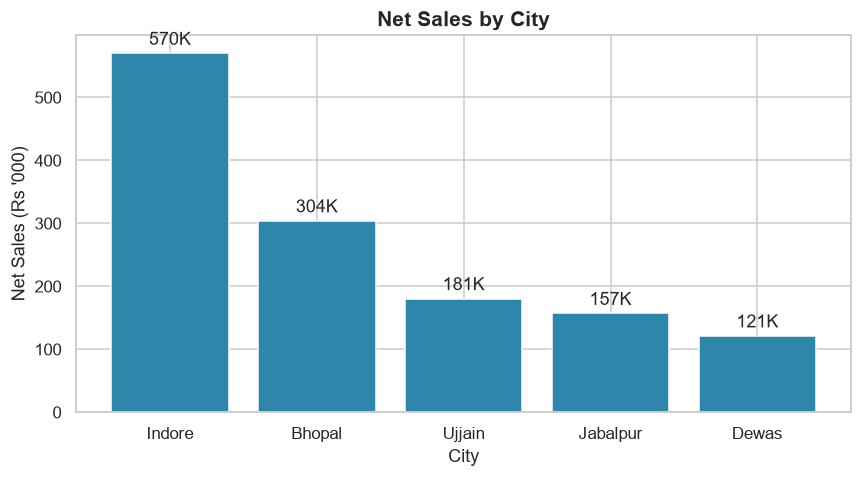

In [16]:
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(city_sales.index, city_sales["net_sales"] / 1000, color="#2E86AB")
ax.bar_label(bars, labels=[f"{v/1000:.0f}K" for v in city_sales["net_sales"]], padding=3)
ax.set_title("Net Sales by City", fontsize=14, fontweight="bold")
ax.set_xlabel("City"); ax.set_ylabel("Net Sales (Rs '000)")
plt.tight_layout(); plt.savefig("charts/1_city_sales.png"); plt.show()

### Chart 2 – Category Share

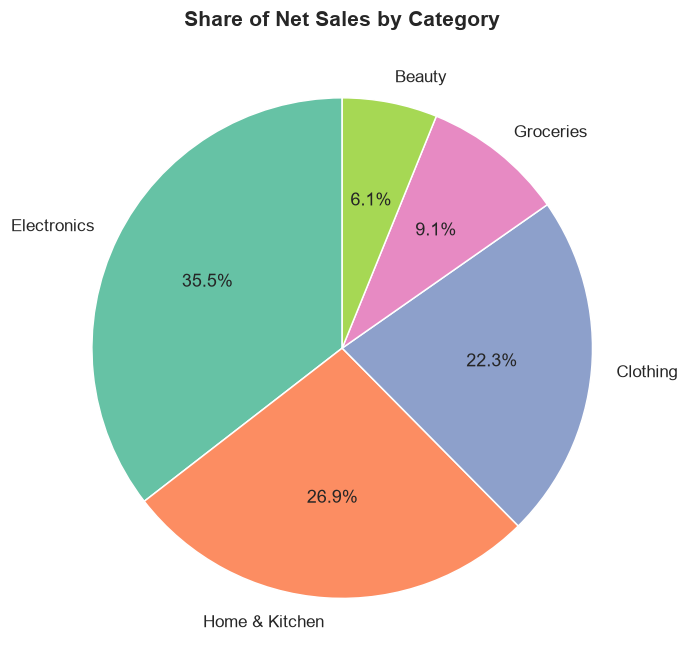

In [17]:
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.pie(cat_sales["net_sales"], labels=cat_sales.index, autopct="%1.1f%%", startangle=90,
       colors=sns.color_palette("Set2"), wedgeprops=dict(edgecolor="white"))
ax.set_title("Share of Net Sales by Category", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.savefig("charts/2_category_share.png"); plt.show()

### Chart 3 – Monthly Sales Trend

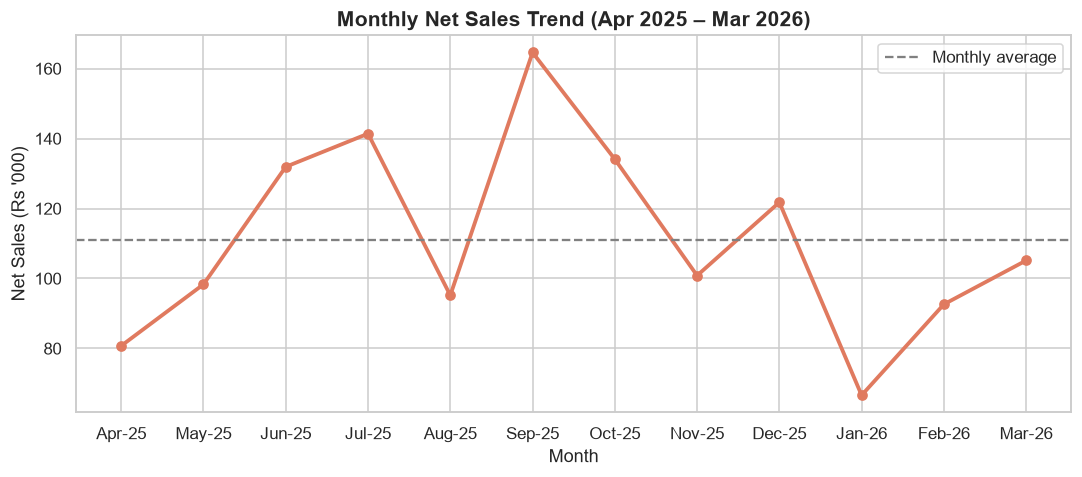

In [18]:
fig, ax = plt.subplots(figsize=(10, 4.5))
labels = month_sales.index.strftime("%b-%y")
ax.plot(labels, month_sales["net_sales"] / 1000, marker="o", linewidth=2.5, color="#E07A5F")
ax.axhline(month_sales["net_sales"].mean() / 1000, ls="--", color="grey", label="Monthly average")
ax.set_title("Monthly Net Sales Trend (Apr 2025 – Mar 2026)", fontsize=14, fontweight="bold")
ax.set_xlabel("Month"); ax.set_ylabel("Net Sales (Rs '000)"); ax.legend()
plt.tight_layout(); plt.savefig("charts/3_monthly_trend.png"); plt.show()

### Chart 4 – Customer Ratings

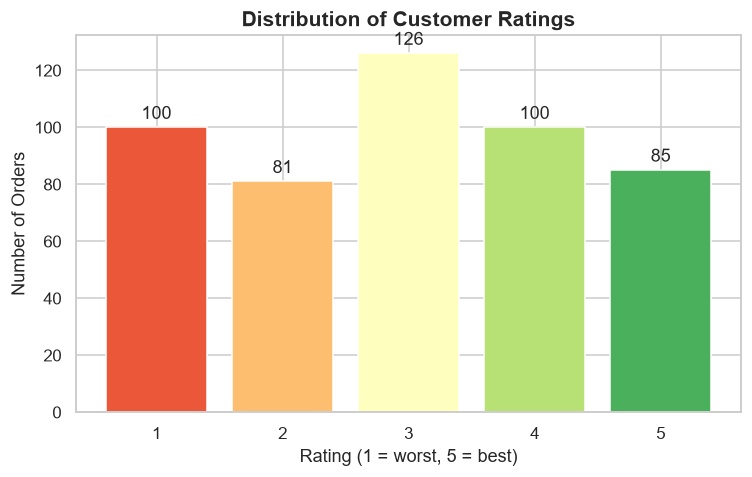

In [19]:
fig, ax = plt.subplots(figsize=(7, 4.5))
rc = df["customer_rating"].value_counts().sort_index()
bars = ax.bar(rc.index.astype(int).astype(str), rc.values, color=sns.color_palette("RdYlGn", 5))
ax.bar_label(bars, padding=3)
ax.set_title("Distribution of Customer Ratings", fontsize=14, fontweight="bold")
ax.set_xlabel("Rating (1 = worst, 5 = best)"); ax.set_ylabel("Number of Orders")
plt.tight_layout(); plt.savefig("charts/4_ratings.png"); plt.show()

### Chart 5 – City × Category Heatmap

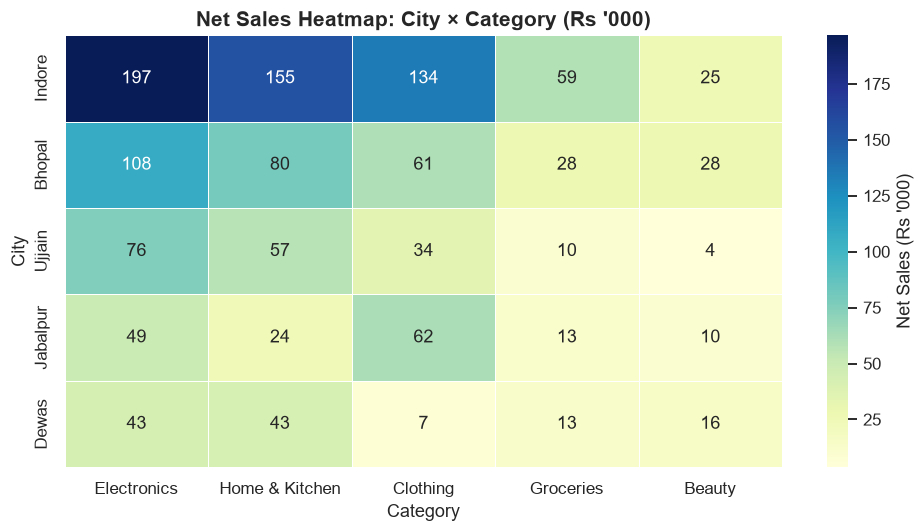

In [20]:
pivot = df.pivot_table(index="city", columns="category", values="net_sales", aggfunc="sum").fillna(0)
pivot = pivot.loc[city_sales.index, cat_sales.index]
fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(pivot / 1000, annot=True, fmt=".0f", cmap="YlGnBu", linewidths=0.5,
            cbar_kws={"label": "Net Sales (Rs '000)"}, ax=ax)
ax.set_title("Net Sales Heatmap: City × Category (Rs '000)", fontsize=14, fontweight="bold")
ax.set_xlabel("Category"); ax.set_ylabel("City")
plt.tight_layout(); plt.savefig("charts/5_heatmap.png"); plt.show()

### Chart 6 (extra) – Top 5 Products & Payment Modes

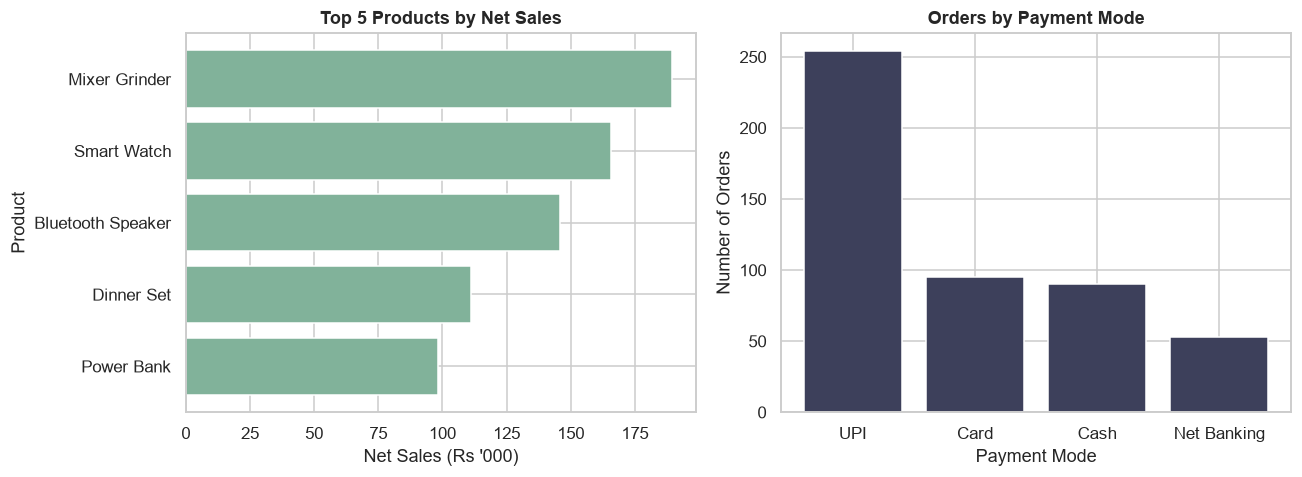

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
t = top5.reset_index().sort_values("net_sales")
axes[0].barh(t["product"], t["net_sales"] / 1000, color="#81B29A")
axes[0].set_title("Top 5 Products by Net Sales", fontweight="bold")
axes[0].set_xlabel("Net Sales (Rs '000)"); axes[0].set_ylabel("Product")
pm = df["payment_mode"].value_counts()
axes[1].bar(pm.index, pm.values, color="#3D405B")
axes[1].set_title("Orders by Payment Mode", fontweight="bold")
axes[1].set_xlabel("Payment Mode"); axes[1].set_ylabel("Number of Orders")
plt.tight_layout(); plt.savefig("charts/6_products_payment.png"); plt.show()

## 6. Summary numbers used in the insights

In [22]:
best_m, worst_m = month_sales["net_sales"].idxmax(), month_sales["net_sales"].idxmin()
low = (df["customer_rating"] <= 2).mean() * 100
print(f"Top city        : {city_sales.index[0]} ({city_sales['share_%'].iloc[0]}% of sales)")
print(f"Top 2 cities    : {city_sales['share_%'].iloc[:2].sum():.1f}% of sales")
print(f"Top category    : {cat_sales.index[0]} ({cat_sales['share_%'].iloc[0]}%)")
print(f"Best month      : {best_m} (Rs {month_sales['net_sales'].max():,.0f})")
print(f"Weakest month   : {worst_m} (Rs {month_sales['net_sales'].min():,.0f})")
print(f"UPI share       : {(df['payment_mode']=='UPI').mean()*100:.1f}% of orders")
print(f"Low ratings (<=2): {low:.1f}% of orders")
print(f"Orders/customer : {total_orders/unique_customers:.2f}")

Top city        : Indore (42.8% of sales)
Top 2 cities    : 65.6% of sales
Top category    : Electronics (35.5%)
Best month      : 2025-09 (Rs 164,598)
Weakest month   : 2026-01 (Rs 66,626)
UPI share       : 51.6% of orders
Low ratings (<=2): 36.8% of orders
Orders/customer : 2.93


## 7. Key Insights
1. **Indore is the biggest market** – Indore brings in 42.8% of net sales (Rs 5.70 lakh). Together with Bhopal (22.8%), two cities make up about two-thirds of the business, so the business depends heavily on them.
2. **Electronics and Home & Kitchen earn the most** – Electronics (35.5%) and Home & Kitchen (26.9%) together give over 62% of sales. Groceries has the most orders (146) but only 9.1% of sales, because each grocery bill is small.
3. **A few high-value products lead** – Mixer Grinder (Rs 1.89 lakh), Smart Watch (Rs 1.66 lakh), Bluetooth Speaker, Dinner Set and Power Bank are the top 5 products. All are in Electronics or Home & Kitchen.
4. **Sales peak in Jun–Oct and dip in Jan** – September was the best month (Rs 1.65 lakh), helped by the festive season, and Jun–Oct stayed strong. January was the weakest month (Rs 0.67 lakh, about 40% below the monthly average).
5. **Customer satisfaction is a concern** – The average rating is only 2.98/5, and 36.8% of orders were rated 1 or 2 stars. Groceries (2.80) and Jabalpur (2.79) have the lowest ratings, while Ujjain (3.36) and Home & Kitchen (3.38) have the highest.
6. **Customers prefer UPI, and bigger discounts don't bring bigger bills** – 51.6% of orders are paid by UPI. Orders with no discount average Rs 3,094, while orders with a 15–20% discount average only about Rs 2,350. This means discounts are not increasing order size.

## 8. Recommendations for the Owner
1. **Fix customer satisfaction first** – Collect feedback from customers who gave 1–2 stars, especially for Groceries and in Jabalpur. Check product quality, delivery time and freshness. Better ratings will bring repeat customers (each customer currently orders only about 3 times a year).
2. **Focus stock and promotions on high-value products and the festive season** – Keep enough stock of Mixer Grinders, Smart Watches, Speakers and Dinner Sets before Jun–Oct. Run a 'New Year / Winter Sale' or combo offers in January–February to fill the slow period.
3. **Use smarter, targeted discounts and grow the smaller cities** – Replace flat 15–20% discounts with UPI cashback or 'buy-more-save-more' offers (e.g. Groceries + Home & Kitchen combos) to raise order value. Use Ujjain's high satisfaction to grow there, and promote Electronics and Clothing in Dewas, where Clothing sales are very low.

## 9. Conclusion
RetailMart earned about **Rs 13.3 lakh** from 492 valid orders across 168 customers. Most of that comes from Indore, from Electronics and Home & Kitchen, and from the Jun–Oct season. The main risk is customer satisfaction: about a third of orders were rated 1 or 2. Fixing that and spending the marketing budget where the sales already are should give the best returns.